# Module 6 — Transformers and Attention Mechanisms

## Lesson 6.5 — Building a Decoder-Only Transformer


We now have every part. Note 6.2 turned text into token IDs and batches; Note 6.3 built multi-head causal self-attention; Note 6.4 wrapped it with a feed-forward network, residual connections and layer normalisation into a Transformer block, and showed why pre-norm is the safe choice. In Note 6.1 we saw a complete Transformer working, built from PyTorch's ready-made layers.

In this note we put our own parts together into a complete **decoder-only Transformer language model**: the same design, at miniature scale, as GPT-style models. We will trace data through it, see how its output becomes a probability distribution over the next character, and run the checks that a careful engineer runs on any new model *before* spending time training it: is the starting loss sensible, does the causal mask really block the future, and can the model learn at all?

Training it properly, and generating text with it, is the subject of Note 6.6.

**Key question:** *How do the components assemble into a complete language model, and how do we know it is built correctly?*

### Learning objectives
- assemble embeddings, Transformer blocks, a final norm and an output head into a decoder-only model;
- trace the shape of the data through the full model;
- explain how logits become a probability distribution over the vocabulary, and what loss to expect before training;
- verify that a causal model cannot see the future;
- use the "overfit one batch" sanity check;
- explain how encoder–decoder models differ, including cross-attention.

### Prerequisites

 read Notes 6.2 to 6.4.

### Setup

Run this cell first. Nothing in this note takes more than a few seconds.

**Environment and results.** The saved outputs record one CPU reference run; random seeds reduce variation but do not guarantee identical numbers across computers. Read the comparisons as evidence from that run. Training times depend on your hardware.

If packages are missing, install them into your notebook environment, then restart the kernel and run from the beginning:

```text
%pip install torch==2.14.1 numpy==2.5.4 pandas==3.0.6 matplotlib==3.11.2 scikit-learn==1.9.1 scipy==1.18.1
```

In [1]:
import os, math, urllib.request
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(0)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cu130


## 1. The Big Picture: Assembling the Components

A decoder-only language model is a stack of the pieces you already know, in this order:

1. **Token embedding:** each character ID becomes a 64-number vector.
2. **Position embedding:** a learned vector for each position (0 to 63) is added.
3. **Transformer blocks × 3:** pre-norm blocks with causal multi-head self-attention and a feed-forward network, exactly as in Note 6.4.
4. **Final layer norm:** with pre-norm blocks, the residual stream itself is never normalised, so we normalise it once at the end.
5. **Output head:** a linear layer from 64 numbers to one score per vocabulary entry.

First we load the data and the batch function from Note 6.2.

In [2]:
PATH = "data/shakespeare/input.txt"
os.makedirs("data/shakespeare", exist_ok=True)
if not os.path.exists(PATH):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", PATH)
text = open(PATH, encoding="utf-8").read()
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(itos[i] for i in ids)
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data)); train_ids, val_ids = data[:n], data[n:]
def get_batch(split, batch_size, context, generator):
    d = train_ids if split == "train" else val_ids
    starts = torch.randint(0, len(d) - context - 1, (batch_size,), generator=generator)
    return torch.stack([d[s:s + context] for s in starts]), torch.stack([d[s + 1:s + context + 1] for s in starts])
print("vocabulary:", len(chars), "| training tokens:", len(train_ids), "| validation tokens:", len(val_ids))

vocabulary: 65 | training tokens: 1003854 | validation tokens: 111540


Now the model. The attention and block classes are the ones from Notes 6.3 and 6.4, written compactly. The `GPT` class assembles them. Two details are worth noticing:

- `forward` accepts optional `targets`. If they are given, the model also computes the **cross-entropy loss**, comparing its predictions at every position with the true next characters. This keeps the training loop in Note 6.6 short.
- The `assert` refuses sequences longer than the context window, because there is no position embedding for position 64 or beyond. A clear error message here saves a confusing one later.

In [3]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.proj = nn.Linear(d_model, d_model)
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).split(D, dim=2)
        q, k, v = [t.view(B, T, self.n_heads, D // self.n_heads).transpose(1, 2) for t in (q, k, v)]
        out = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.proj(out.transpose(1, 2).reshape(B, T, D))

class Block(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads)
        self.ffn = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.ffn(self.ln2(x))

class GPT(nn.Module):
    """A small decoder-only Transformer language model."""
    def __init__(self, vocab_size, d_model=64, n_heads=4, n_layers=3, context=64):
        super().__init__()
        self.context = context
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(context, d_model)
        self.blocks = nn.ModuleList([Block(d_model, n_heads) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)
    def forward(self, ids, targets=None):
        B, T = ids.shape
        assert T <= self.context, f"sequence of {T} tokens is longer than the context of {self.context}"
        x = self.tok_emb(ids) + self.pos_emb(torch.arange(T, device=ids.device))   # (B, T, D)
        for block in self.blocks:
            x = block(x)                                                            # (B, T, D)
        logits = self.head(self.ln_f(x))                                            # (B, T, vocab)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

torch.manual_seed(0)
model = GPT(len(chars))
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 162561


The complete model has 162,561 parameters, exactly the same as the version we built from PyTorch's ready-made layers in Note 6.1. Same design, same size; the difference is that now we have written every part ourselves.

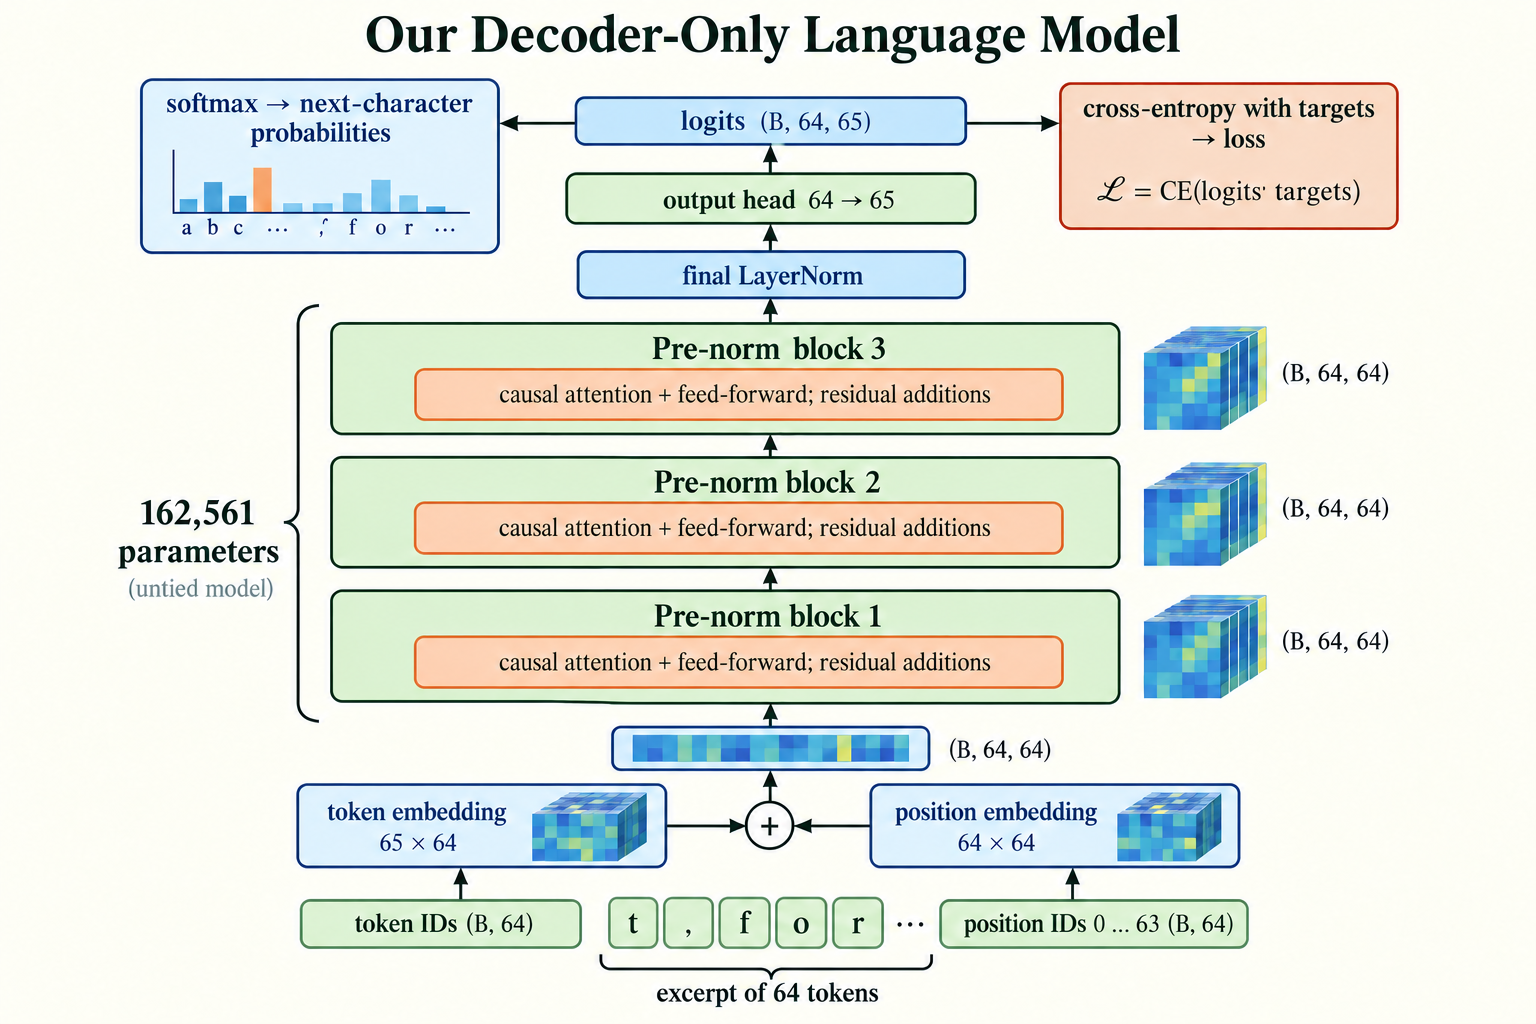

*Figure 6.5.1. The untied reference model has 162,561 parameters. A 64-token input produces logits of shape (B, 64, 65). Cross-entropy consumes raw logits during training; softmax converts them to probabilities for inspection or sampling.*

## 2. From Input Tokens to Output Predictions

Let's pass a batch of 4 training windows through the model one stage at a time and print the shape after each stage.

In [4]:
g = torch.Generator().manual_seed(0)
x, y = get_batch("train", 4, 64, g)
print(f"{'stage':<26} shape")
print(f"{'token ids':<26} {tuple(x.shape)}")
with torch.no_grad():
    h = model.tok_emb(x); print(f"{'token embeddings':<26} {tuple(h.shape)}")
    p = model.pos_emb(torch.arange(x.shape[1])); print(f"{'position embeddings':<26} {tuple(p.shape)}  (broadcast over the batch)")
    h = h + p; print(f"{'sum':<26} {tuple(h.shape)}")
    for i, block in enumerate(model.blocks):
        h = block(h); print(f"{'after block ' + str(i + 1):<26} {tuple(h.shape)}")
    h = model.ln_f(h); print(f"{'after final layer norm':<26} {tuple(h.shape)}")
    logits = model.head(h); print(f"{'logits':<26} {tuple(logits.shape)}")

stage                      shape
token ids                  (4, 64)
token embeddings           (4, 64, 64)
position embeddings        (64, 64)  (broadcast over the batch)
sum                        (4, 64, 64)
after block 1              (4, 64, 64)
after block 2              (4, 64, 64)
after block 3              (4, 64, 64)
after final layer norm     (4, 64, 64)
logits                     (4, 64, 65)


The journey is short:

- 4 windows of 64 token IDs, `(4, 64)`, become token embeddings of shape `(4, 64, 64)`.
- The position embeddings have shape `(64, 64)`, one vector per position. PyTorch's **broadcasting** (Module 2) adds the same position vectors to every sequence in the batch, so the sum is still `(4, 64, 64)`.
- The three blocks and the final layer norm keep the shape `(4, 64, 64)`.
- The output head turns each 64-number vector into 65 scores: logits of shape `(4, 64, 65)`.

So for every one of the 4 × 64 = 256 positions in the batch, the model produces a full set of scores for what comes next.

> **Common mistake:** confusing the two 64s. In `(4, 64, 64)`, the first 64 is the number of positions (the context) and the second is `d_model`, the vector size. They are equal in our model by coincidence. If you change one, the other must not change with it. When shapes look ambiguous, print them with descriptive labels, or choose different sizes while debugging so that every dimension is distinguishable.

## 3. Output Projections and Probability Distributions

The output head is a single linear layer, but it carries a whole idea: it compares each token's final vector against a learned vector for every entry in the vocabulary and produces a score for each. Higher score, more likely next token. Softmax turns the 65 scores at each position into a **probability distribution**: 65 positive numbers that add up to 1.

Let's look at the prediction at position 10 of the first window.

In [5]:
with torch.no_grad():
    logits, loss = model(x, y)
probs = F.softmax(logits, dim=-1)                       # turn scores into probabilities over the vocabulary
print("probabilities:", tuple(probs.shape), "| each row sums to", round(probs[0, 10].sum().item(), 4))
top = probs[0, 10].topk(5)
print("context so far:", repr(decode(x[0, :11].tolist())), "| true next character:", repr(decode([y[0, 10].item()])))
print("untrained top-5:", [(repr(itos[i.item()]), round(v.item(), 3)) for v, i in zip(top.values, top.indices)])
print("probability given to the true next character:", round(probs[0, 10, y[0, 10]].item(), 4))

probabilities: (4, 64, 65) | each row sums to 1.0
context so far: 't, for his ' | true next character: 'p'
untrained top-5: [("'h'", 0.052), ("'A'", 0.036), ("'!'", 0.036), ("'u'", 0.034), ("'s'", 0.033)]
probability given to the true next character: 0.013


The probabilities have shape `(4, 64, 65)`, and each set of 65 sums to 1.0. At position 10, the model has seen `'t, for his '` and the true next character is `'p'` (the text continues "purpose"). The untrained model's top guesses are `'h'`, `'A'`, `'!'`, `'u'` and `'s'`, each with only about 0.03 to 0.05 probability, and it gives the correct `'p'` just 0.013. As expected, it knows nothing yet.

### 3.1 What loss should an untrained model have?

The cross-entropy loss is the average of −log(probability given to the true next token) over all positions. If the model gave every character the same probability, 1/65, the loss would be −log(1/65) = ln(65). So before training, the loss should be close to that value.

In [6]:
print(f"loss of the untrained model on this batch: {loss.item():.3f}")
print(f"loss of a perfectly uniform guess, ln({len(chars)}): {math.log(len(chars)):.3f}")
with torch.no_grad():
    print(f"spread (std) of the untrained logits: {logits.std().item():.3f}")

loss of the untrained model on this batch: 4.301
loss of a perfectly uniform guess, ln(65): 4.174
spread (std) of the untrained logits: 0.582


The untrained model's loss is 4.301, a little above the uniform-guess value of 4.174. The reason is that its random logits are not all equal: they have a spread of 0.582, so its guesses are slightly confident in random directions, which costs a bit more than guessing uniformly. Close to ln(vocabulary size), and a little above it, is exactly what a healthy, freshly initialised model should show.

This is the first sanity check for any classifier or language model. If the starting loss is far above ln(vocabulary size), something is wrong, usually initial logits that are far too large, or labels that do not match the outputs.

### 3.2 Weight tying

The token embedding table (65 × 64) and the output head's weights (65 × 64) both hold one vector per vocabulary entry: one is used to read tokens in, the other to score tokens out. Many language models **tie** them, using the same matrix for both, which saves parameters and often helps a little.

In [7]:
tied = GPT(len(chars))
tied.head.weight = tied.tok_emb.weight                      # share one matrix between input and output
unique = sum(p.numel() for p in set(tied.parameters()))
print("parameters with separate input and output matrices:", sum(p.numel() for p in model.parameters()))
print("parameters with tied weights:", unique)

parameters with separate input and output matrices: 162561
parameters with tied weights: 158401


Tying removes 4,160 parameters, the size of one 65 × 64 matrix: 162,561 becomes 158,401. In large models with vocabularies of tens of thousands of tokens, the saving is substantial. We keep our model untied for simplicity.

> **Key terms**
> - **Output head:** the final linear layer that turns each vector into one score (logit) per vocabulary entry.
> - **Probability distribution:** a set of non-negative numbers that sum to 1, one per possible outcome.
> - **Cross-entropy loss:** the average of −log(probability of the correct token).
> - **Weight tying:** using the same matrix for the token embedding and the output head.

**Check yourself.**

1. A language model with a vocabulary of 50,000 tokens reports a loss of 10.8 before any training. Is that plausible? (ln(50,000) ≈ 10.82.)

<details>
<summary>Worked answer</summary>

Yes. A loss of 10.8 is almost exactly ln(50,000) ≈ 10.82, the loss of a uniform guess, which is what an untrained model should produce. A value far higher, say 30, would suggest a problem.

</details>

## 4. Implementing a Simplified Transformer with PyTorch: Checking It Works

A new model can have bugs that produce no error message at all: a mask that does not mask, a shift in the wrong direction, a layer that never receives gradients. The model will still train, just badly, and you may lose days wondering why. So before training, we run two quick checks.

### 4.1 Check 1: the model cannot see the future

If the causal mask works, the prediction at position t must depend only on tokens 0 to t. So if we change the token at position 40, the logits at positions 0 to 39 must not change at all, while the logits from position 40 onwards may.

largest change in logits at positions 0-39: 0.00e+00
largest change in logits at positions 40-63: 8.28e-03 (smallest) to 1.36e+00


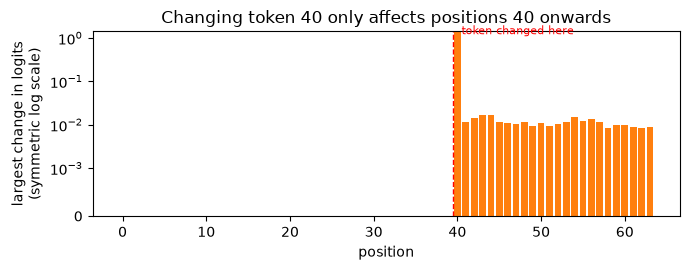

In [8]:
x1 = x[:1].clone(); x2 = x1.clone()
x2[0, 40] = (x2[0, 40] + 1) % len(chars)              # change ONE token, at position 40
with torch.no_grad():
    diff = (model(x1)[0] - model(x2)[0]).abs().amax(dim=-1)[0]   # largest change at each position
print("largest change in logits at positions 0-39:", f"{diff[:40].max().item():.2e}")
print("largest change in logits at positions 40-63:", f"{diff[40:].min().item():.2e} (smallest) to {diff[40:].max().item():.2e}")
plt.figure(figsize=(7, 2.8))
plt.bar(range(64), diff.numpy(), color=["tab:blue"] * 40 + ["tab:orange"] * 24)
plt.axvline(39.5, color="red", ls="--", lw=1); plt.text(40.5, diff.max() * 0.9, "token changed here", color="red", fontsize=8)
plt.yscale("symlog", linthresh=1e-3)
plt.xlabel("position"); plt.ylabel("largest change in logits\n(symmetric log scale)"); plt.title("Changing token 40 only affects positions 40 onwards")
plt.tight_layout(); plt.show()

The largest change at positions 0 to 39 is exactly 0. From position 40 onwards, every position changes, by between 8.28e-03 and 1.36e+00. The biggest change is at position 40 itself, whose own input changed. The later changes are small because the untrained model mixes in context only weakly, but they are there. The causal mask works: no information flows backwards from the future.

If this test ever shows changes before the edited position, the model is leaking future information. During training it would learn to "predict" tokens by reading them, reach a suspiciously low loss, and then generate nonsense.

### 4.2 Check 2: can the model learn at all? Overfit one batch

The second check is a classic: take **one** small batch and train on it repeatedly. A model with enough capacity, a working loss and correctly flowing gradients should be able to **memorise** a single batch almost perfectly. If it cannot, something is broken in the training pipeline, and there is no point training on the full dataset yet.

loss on the single batch: start 4.301 | step 100 0.01 | step 300 0.007
loss of the same model on a different batch: 7.281


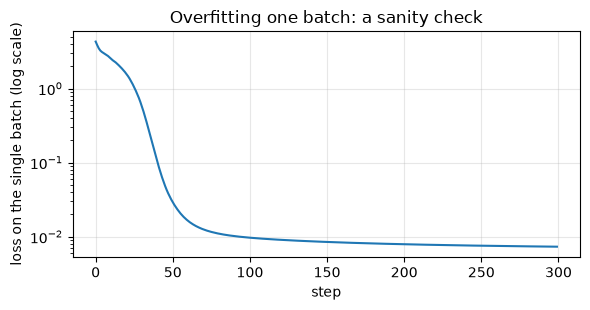

In [9]:
torch.manual_seed(0)
probe = GPT(len(chars))
opt = torch.optim.AdamW(probe.parameters(), lr=3e-3)
xb, yb = get_batch("train", 8, 64, torch.Generator().manual_seed(1))     # ONE fixed batch
history = []
for step in range(300):
    _, loss = probe(xb, yb)
    opt.zero_grad(); loss.backward(); opt.step()
    history.append(loss.item())
print("loss on the single batch: start", round(history[0], 3), "| step 100", round(history[99], 3),
      "| step 300", round(history[-1], 3))
with torch.no_grad():
    _, other = probe(*get_batch("val", 8, 64, torch.Generator().manual_seed(2)))
print("loss of the same model on a different batch:", round(other.item(), 3))
plt.figure(figsize=(6, 3.2)); plt.plot(history); plt.yscale("log")
plt.xlabel("step"); plt.ylabel("loss on the single batch (log scale)"); plt.title("Overfitting one batch: a sanity check")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

On the single batch, the loss falls from 4.301 to 0.01 by step 100 and 0.007 by step 300: the model has memorised it almost perfectly, so gradients are flowing and every part can learn.

But look at the last line. On a *different* batch, the same model's loss is 7.281, far worse than an untrained model's 4.301. It has not learned Shakespeare; it has memorised 8 windows and become confidently wrong about everything else. This is overfitting in its most extreme form, and it is exactly what the check is designed to produce. A sanity check, not a training method.

### 4.3 Generating text from the untrained model

Finally, let's see what the model writes before training. Generation works one token at a time: run the model on the text so far, take the probability distribution at the **last** position, draw the next character from it, append it, and repeat. (We keep at most the last 64 characters, the context window.) Note 6.6 covers this process, and better ways to choose the next token, in detail.

In [10]:
@torch.no_grad()
def generate(model, prompt, n_new, generator):
    ids = torch.tensor([encode(prompt)])
    for _ in range(n_new):
        logits, _ = model(ids[:, -model.context:])           # never feed more than the context
        probs = F.softmax(logits[:, -1], dim=-1)             # distribution for the NEXT token only
        nxt = torch.multinomial(probs, 1, generator=generator)
        ids = torch.cat([ids, nxt], dim=1)
    return decode(ids[0].tolist())
print(generate(model, "ROMEO:\n", 120, torch.Generator().manual_seed(0)))

ROMEO:
t3ZrjmhPkq ARxLsX?tUWHoHcG
mexhAyU&NNdkIxAlst,BUMycofD$BygOOfntw
kerM h&?j DJPbsO;HevC!BTg3fhhPbjslwa-H3KypMrWwXkMvRJjRc


After the prompt "ROMEO:", the untrained model produces random characters: capitals, punctuation and letters with no structure at all. Every piece of the model works; it simply has not learned anything yet. That is the starting point for Note 6.6.

> **Common mistake:** skipping sanity checks to save time. Checking the initial loss, the causal mask and the overfit-one-batch behaviour takes seconds. Discovering a broken mask after hours of training wastes far more time, and a silent bug may never be discovered at all.

**Check yourself.**

1. A colleague's overfit-one-batch test gets stuck at a loss of 3.3 and never goes lower. Name two things that might be wrong.

<details>
<summary>Worked answer</summary>

Possible causes include: the targets are not aligned with the inputs (for example, not shifted, or shifted the wrong way); gradients are not reaching the parameters (for example, `optimizer.zero_grad()`, `loss.backward()` or `optimizer.step()` is missing, or the optimizer was given the wrong parameters); the learning rate is far too high or too low; or the model has collapsed to predicting character frequencies, which is what a loss of about 3.3 suggests on this dataset.

</details>

## 5. How Encoders, Cross-Attention and Encoder–Decoder Models Differ

Our model is decoder-only. Here is how the other two families from Note 6.1 would differ from what we built, in terms of code:

- **An encoder-only model** uses the same blocks **without the causal mask**: in our attention class, `is_causal=True` becomes `False`. Every token then sees the whole input. The output head is usually replaced too: for classification, the token vectors are pooled into one vector and a small head predicts the class.
- **An encoder–decoder model** has two stacks. The encoder is a stack of unmasked blocks that reads the source sequence. The decoder is a stack like ours, but each decoder block has a **third sub-layer**, between self-attention and the feed-forward network: **cross-attention**.

In cross-attention, the **queries** come from the decoder's tokens, while the **keys and values** come from the encoder's output. So each target token asks "which parts of the source are relevant to me?" and gathers information from them. No causal mask is needed there, because the whole source is known in advance.

In [11]:
torch.manual_seed(0)
cross = nn.MultiheadAttention(64, 4, batch_first=True)
encoder_out = torch.randn(1, 10, 64)          # 10 source tokens, already processed by an encoder
decoder_x = torch.randn(1, 7, 64)             # 7 target tokens generated so far
out, w = cross(query=decoder_x, key=encoder_out, value=encoder_out)
print("cross-attention output:", tuple(out.shape), "| weights:", tuple(w.shape))
print("each target token's weights over the 10 source tokens sum to:", [round(v, 3) for v in w[0].sum(-1).tolist()])

cross-attention output: (1, 7, 64) | weights: (1, 7, 10)
each target token's weights over the 10 source tokens sum to: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


Seven decoder tokens attend over ten encoder outputs. The output has one vector per **decoder** token, `(1, 7, 64)`, and the weights have shape `(1, 7, 10)`: for each of the 7 target tokens, a distribution over the 10 source tokens, each summing to 1.0. Translating "the cat sat" into French, the token being generated for "chat" would, after training, place most of its weight on "cat".

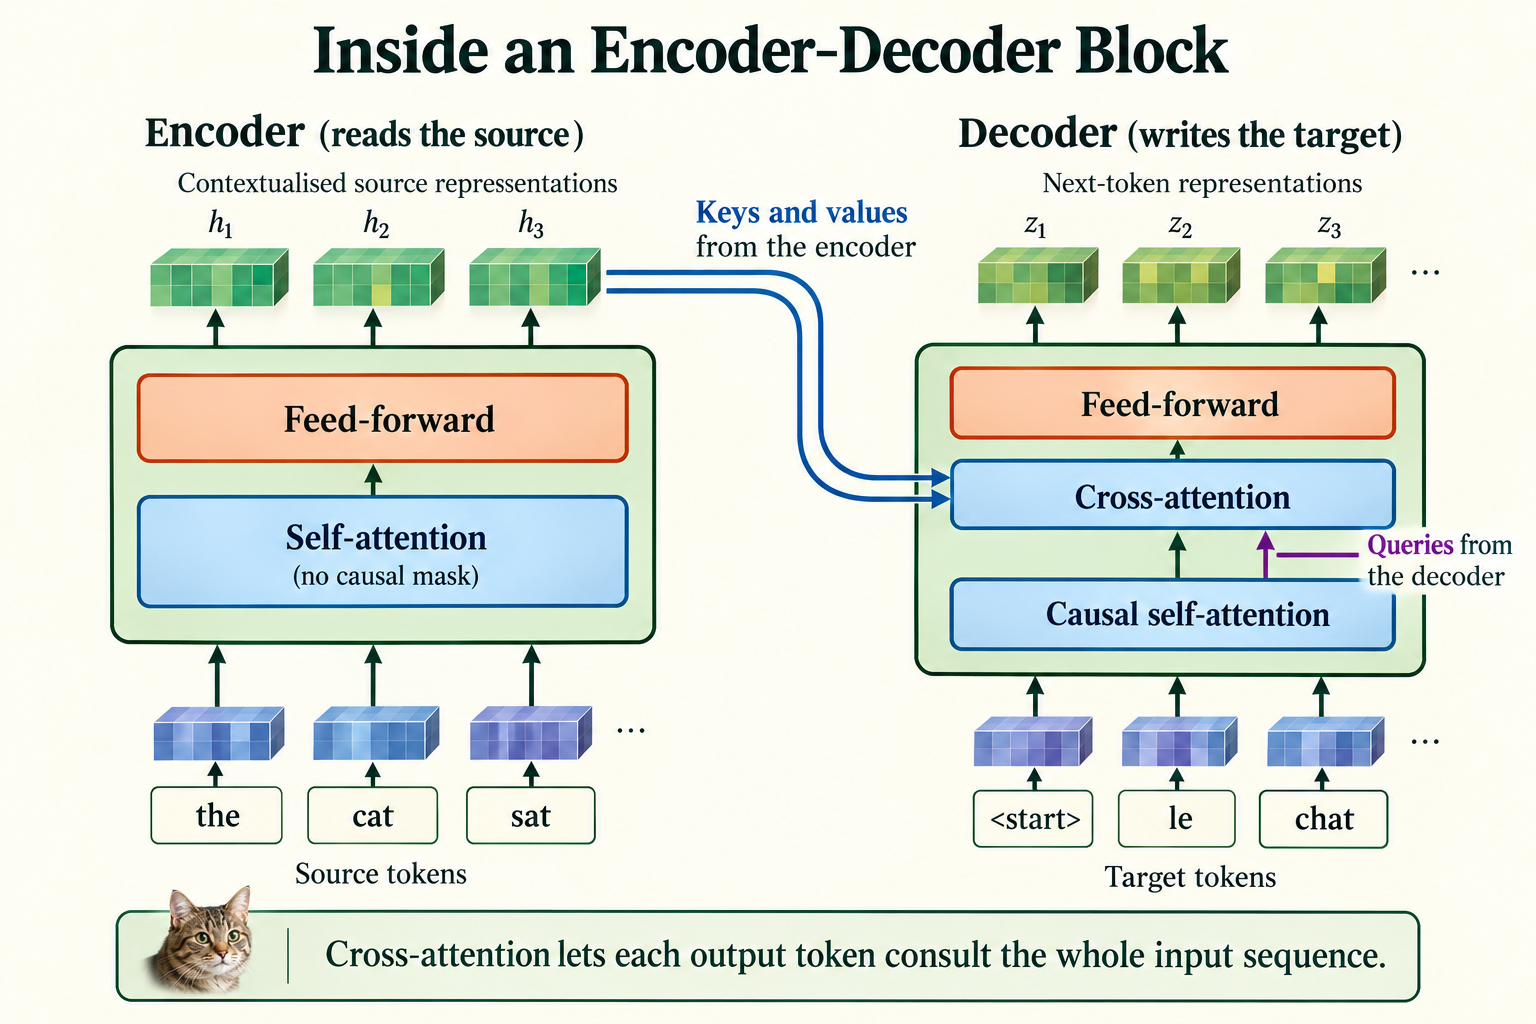

*Figure 6.5.2. Decoder queries attend to keys and values from encoded source tokens. Target self-attention is causal; source self-attention is bidirectional apart from any padding mask. Residual connections and norms are omitted for clarity.*

> **Key terms**
> - **Cross-attention:** attention in which queries come from one sequence (the decoder's) and keys and values from another (the encoder's output).

**Check yourself.**

1. Why does cross-attention not need a causal mask, while the decoder's self-attention does?

<details>
<summary>Worked answer</summary>

During translation, the entire source sentence is available from the start, so letting every target token see all of it is legitimate. The decoder's self-attention looks at the target sequence itself, which is being generated one token at a time; during training, a target token must not see the target tokens after it, or it could simply read the answer.

</details>

## Putting It All Together

Our decoder-only language model assembles every component of Module 6: token and position embeddings, three pre-norm Transformer blocks with causal attention, a final layer norm and an output head, 162,561 parameters in all. Data flows from `(4, 64)` token IDs to `(4, 64, 64)` vectors, through the blocks unchanged in shape, to `(4, 64, 65)` logits: a full next-character distribution at all 256 positions in one pass.

Before training, we checked it:

- The **initial loss** was 4.301, just above ln(65) = 4.174, as expected for random logits with a spread of 0.582.
- **No future leakage:** changing the token at position 40 left positions 0 to 39 exactly unchanged.
- **It can learn:** on a single batch the loss fell from 4.301 to 0.007, while the loss on unseen data rose to 7.281, a vivid illustration of memorisation.

The untrained model writes random characters. Encoder-only models would drop the causal mask; encoder–decoder models add a cross-attention sub-layer in which decoder queries consult the encoder's outputs. In Note 6.6 we train our model on Tiny Shakespeare and teach it to write.

## Summary

- A decoder-only language model is: token embedding + position embedding → stacked pre-norm blocks with causal attention → final layer norm → output head.
- The output head produces one logit per vocabulary entry at every position; softmax turns them into a probability distribution.
- The cross-entropy loss of an untrained model should be close to ln(vocabulary size); ours was 4.301 against 4.174.
- **Weight tying** shares the embedding and output matrices, saving parameters (4,160 here).
- Always verify a new model before training: check the initial loss, check that changing a later token never affects earlier predictions, and check that the model can overfit one batch.
- Overfitting one batch drives that batch's loss towards zero while the loss on other data gets worse.
- Encoder-only models remove the causal mask; encoder–decoder models add **cross-attention**, with decoder queries and encoder keys and values.

## Glossary

| Term | Meaning |
|---|---|
| Decoder-only model | A Transformer of causal blocks that predicts each next token from the earlier ones. |
| Output head | The linear layer mapping each vector to one logit per vocabulary entry. |
| Logits | Raw scores before softmax. |
| Probability distribution | Non-negative numbers summing to 1, one per outcome. |
| Cross-entropy loss | Average of −log(probability assigned to the correct token). |
| Broadcasting | PyTorch's automatic expansion of a smaller tensor to match a larger one, e.g. position embeddings across a batch. |
| Weight tying | Using one matrix for both the token embedding and the output head. |
| Future leakage | A bug in which predictions can use tokens that come later in the sequence. |
| Overfit-one-batch test | Training on one small batch to confirm the model and pipeline can learn. |
| Memorisation | Fitting specific training examples without learning patterns that generalise. |
| Cross-attention | Attention with queries from the decoder and keys and values from the encoder. |